### A Python notebook that compares models for predicting student grades or academic-performance categories.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [54]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score , confusion_matrix , classification_report , mean_squared_error , r2_score

In [55]:
ds = pd.read_csv('student_performance_dataset.csv')

In [56]:
type(ds)

pandas.core.frame.DataFrame

In [57]:
ds.head

<bound method NDFrame.head of     Student_ID  Gender  Study_Hours_per_Week  Attendance_Rate  \
0         S147    Male                    31        68.267841   
1         S136    Male                    16        78.222927   
2         S209  Female                    21        87.525096   
3         S458  Female                    27        92.076483   
4         S078  Female                    37        98.655517   
..         ...     ...                   ...              ...   
703       S492    Male                    14        84.658761   
704       S301    Male                    35        60.278990   
705       S473    Male                    25        98.384969   
706       S307  Female                    21        96.148012   
707       S046  Female                    22        80.404392   

     Past_Exam_Scores Parental_Education_Level Internet_Access_at_Home  \
0                  86              High School                     Yes   
1                  73                    

In [58]:
ds.columns

Index(['Student_ID', 'Gender', 'Study_Hours_per_Week', 'Attendance_Rate',
       'Past_Exam_Scores', 'Parental_Education_Level',
       'Internet_Access_at_Home', 'Extracurricular_Activities',
       'Final_Exam_Score', 'Pass_Fail'],
      dtype='object')

### drop the 3 columns

In [59]:
ds = ds.drop(columns = ['Parental_Education_Level',
       'Internet_Access_at_Home', 'Extracurricular_Activities',])

In [60]:
ds.columns

Index(['Student_ID', 'Gender', 'Study_Hours_per_Week', 'Attendance_Rate',
       'Past_Exam_Scores', 'Final_Exam_Score', 'Pass_Fail'],
      dtype='object')

In [61]:
ds.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 708 entries, 0 to 707
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Student_ID            708 non-null    object 
 1   Gender                708 non-null    object 
 2   Study_Hours_per_Week  708 non-null    int64  
 3   Attendance_Rate       708 non-null    float64
 4   Past_Exam_Scores      708 non-null    int64  
 5   Final_Exam_Score      708 non-null    int64  
 6   Pass_Fail             708 non-null    object 
dtypes: float64(1), int64(3), object(3)
memory usage: 38.8+ KB


#### replace the valuse pass = 1 and fail = 0 & Makle = 1 & Female = 2

In [11]:
ds['Pass_Fail'] = ds['Pass_Fail'].replace({"Pass": "1", "Fail": "0" })
ds['Gender'] = ds['Gender'].replace({"Male" : "1" , "Female" : "2"})

In [12]:
ds.head

<bound method NDFrame.head of     Student_ID Gender  Study_Hours_per_Week  Attendance_Rate  \
0         S147      1                    31        68.267841   
1         S136      1                    16        78.222927   
2         S209      2                    21        87.525096   
3         S458      2                    27        92.076483   
4         S078      2                    37        98.655517   
..         ...    ...                   ...              ...   
703       S492      1                    14        84.658761   
704       S301      1                    35        60.278990   
705       S473      1                    25        98.384969   
706       S307      2                    21        96.148012   
707       S046      2                    22        80.404392   

     Past_Exam_Scores  Final_Exam_Score Pass_Fail  
0                  86                63         1  
1                  73                50         0  
2                  74                55      

In [13]:
ds = ds.sort_values(by='Student_ID')
ds.tail(2)

,Student_ID,Gender,Study_Hours_per_Week,Attendance_Rate,Past_Exam_Scores,Final_Exam_Score,Pass_Fail
74,S499,1,24,73.660506,68,57,0
659,S500,2,26,65.642743,71,52,0


## replace the string from student id S001 --> 001 usinf str.replace

In [14]:
ds['Student_ID'] = ds['Student_ID'].str.replace('S', '', regex=False)
ds.head(2)

,Student_ID,Gender,Study_Hours_per_Week,Attendance_Rate,Past_Exam_Scores,Final_Exam_Score,Pass_Fail
366,001,1,38,68.836948,64,50,0
573,002,2,30,87.478915,56,50,0


### after that convert string to int and then make aa group of 50 50 student (add column for group)

In [15]:
ds["Student_ID"] = ds["Student_ID"].astype(int)
ds.head(2)
# print(ds[["Student_ID", "Student_Group"]].head(10))

,Student_ID,Gender,Study_Hours_per_Week,Attendance_Rate,Past_Exam_Scores,Final_Exam_Score,Pass_Fail
366,1,1,38,68.836948,64,50,0
573,2,2,30,87.478915,56,50,0


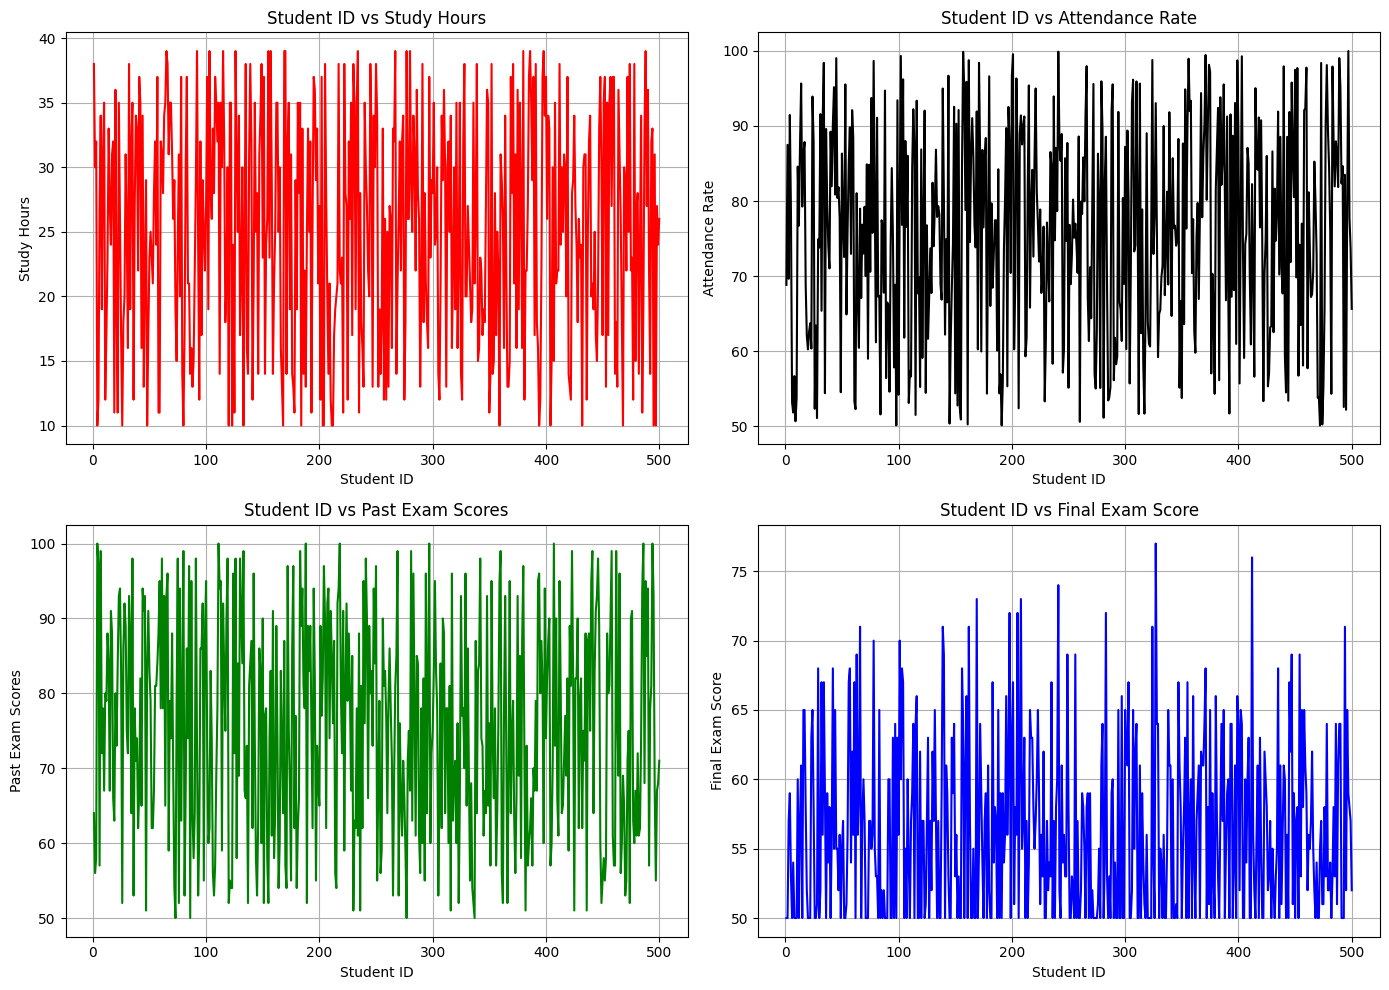

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 10))

# Graph 1: Study Hours
plt.subplot(2, 2, 1)
plt.plot(ds["Student_ID"], ds["Study_Hours_per_Week"], color="red")
plt.title("Student ID vs Study Hours")
plt.xlabel("Student ID")
plt.ylabel("Study Hours")
plt.grid()

# Graph 2: Attendance Rate
plt.subplot(2, 2, 2)
plt.plot(ds["Student_ID"], ds["Attendance_Rate"], color="black")
plt.title("Student ID vs Attendance Rate")
plt.xlabel("Student ID")
plt.ylabel("Attendance Rate")
plt.grid()

# Graph 3: Past Exam Scores
plt.subplot(2, 2, 3)
plt.plot(ds["Student_ID"], ds["Past_Exam_Scores"], color="green")
plt.title("Student ID vs Past Exam Scores")
plt.xlabel("Student ID")
plt.ylabel("Past Exam Scores")
plt.grid()

# Graph 4: Final Exam Score
plt.subplot(2, 2, 4)
plt.plot(ds["Student_ID"], ds["Final_Exam_Score"], color="blue")
plt.title("Student ID vs Final Exam Score")
plt.xlabel("Student ID")
plt.ylabel("Final Exam Score")
plt.grid()

plt.tight_layout()
plt.show()

In [17]:
cols = [
    "Study_Hours_per_Week",
    "Attendance_Rate",
    "Past_Exam_Scores",
    "Final_Exam_Score",
    "Pass_Fail"
]

corr = ds[cols].corr()

print(corr)

                      Study_Hours_per_Week  Attendance_Rate  Past_Exam_Scores  \
Study_Hours_per_Week              1.000000        -0.008150         -0.014756   
Attendance_Rate                  -0.008150         1.000000          0.000412   
Past_Exam_Scores                 -0.014756         0.000412          1.000000   
Final_Exam_Score                  0.370387         0.460478          0.489516   
Pass_Fail                         0.296769         0.396283          0.436607   

                      Final_Exam_Score  Pass_Fail  
Study_Hours_per_Week          0.370387   0.296769  
Attendance_Rate               0.460478   0.396283  
Past_Exam_Scores              0.489516   0.436607  
Final_Exam_Score              1.000000   0.864175  
Pass_Fail                     0.864175   1.000000  


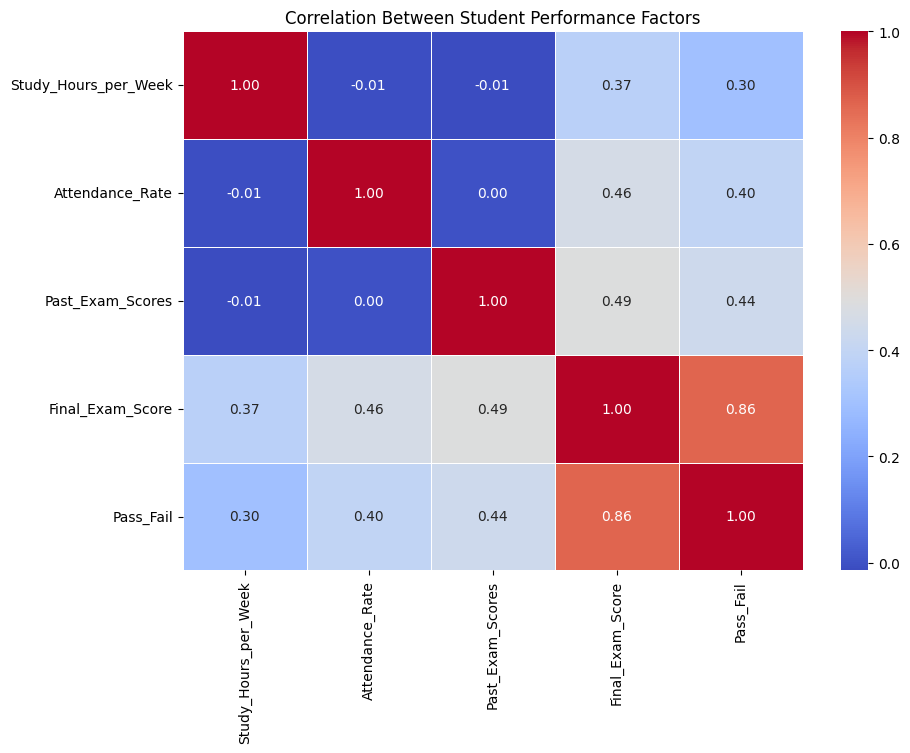

In [18]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    linewidths=0.5,
    fmt=".2f"
)

plt.title("Correlation Between Student Performance Factors")
plt.show()

In [19]:
x = ds.iloc[: , 2 : 5]
y = ds["Pass_Fail"]

In [20]:
train_x , test_x , train_y , test_y = train_test_split(
    x , y , test_size = 0.2 , random_state = 42
)

In [21]:
LR = LinearRegression()

In [22]:
LR.fit(train_x , train_y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [23]:
y_pred = LR.predict(test_x)

In [24]:
for actual , predict in zip( test_y[: 6] , y_pred[:6]):
    print("actual: " , actual , "predict" , predict)


actual:  1 predict 0.26154396180026174
actual:  0 predict 0.33984003555476283
actual:  1 predict 0.5311680820668703
actual:  0 predict -0.2016867914236311
actual:  0 predict 0.4861135342684517
actual:  0 predict 0.6316581959367764


In [25]:
# from sklearn.metrics import mean_absolute_error , mean_sqaured_error , r2_score
from sklearn.metrics import mean_absolute_error , mean_squared_error , r2_score

In [26]:
MAE = mean_absolute_error(test_y , y_pred)
MSE = mean_squared_error(test_y, y_pred)
R2 = r2_score(test_y , y_pred)

In [27]:
print("MAE: " , MAE)
print("MSE :" , MSE)
print("R2_socre : " , R2)

MAE:  0.3160466862693624
MSE : 0.14698753254795494
R2_socre :  0.41204986980818026


In [29]:
LR2 = LinearRegression()

In [31]:
poly = PolynomialFeatures(degree = 2)

In [34]:
x_train_poly = poly.fit_transform(train_x)

In [35]:
x_test_poly = poly.transform(test_x)

In [36]:
LR2.fit(x_train_poly , train_y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [37]:
y_pred_poly = LR2.predict(x_test_poly)

In [38]:
mae = mean_absolute_error(test_y , y_pred_poly)
mse = mean_squared_error(test_y ,y_pred_poly)
R2 = r2_score(test_y , y_pred_poly)

In [39]:
print("MAE :" , mae)
print("MSE :" , mse)
print("R2 : " , R2)

MAE : 0.31527959741391054
MSE : 0.14562211729585053
R2 :  0.41751153081659786


## work Random Forest models

In [44]:
RF = RandomForestClassifier(
    n_estimators = 50,
    random_state = 42
)


In [45]:
RF.fit(train_x , train_y)

,n_estimators,50
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [46]:
y_pred_RF = RF.predict(test_x)

In [52]:
y_pred_RF

array(['1', '0', '1', '0', '0', '1', '1', '1', '0', '1', '0', '0', '0',
       '0', '1', '1', '0', '0', '1', '0', '1', '0', '0', '0', '0', '1',
       '0', '1', '1', '1', '0', '0', '1', '1', '1', '1', '1', '1', '1',
       '0', '0', '0', '0', '1', '1', '0', '1', '1', '0', '1', '1', '1',
       '0', '1', '1', '1', '1', '1', '0', '1', '0', '0', '0', '1', '1',
       '1', '0', '0', '0', '0', '1', '1', '1', '1', '1', '0', '0', '1',
       '1', '1', '0', '0', '1', '0', '0', '0', '0', '0', '1', '0', '0',
       '0', '1', '0', '1', '0', '1', '0', '1', '0', '0', '1', '0', '1',
       '1', '0', '1', '0', '1', '0', '1', '1', '1', '1', '1', '0', '1',
       '1', '0', '0', '0', '1', '1', '1', '1', '1', '1', '0', '1', '0',
       '0', '0', '0', '1', '0', '1', '0', '1', '0', '1', '0', '0'],
      dtype=object)

In [53]:
for actual , predict in zip( test_y[: 6] , y_pred_RF[:6]):
    print("actual: " , actual , "predict" , predict)

actual:  1 predict 1
actual:  0 predict 0
actual:  1 predict 1
actual:  0 predict 0
actual:  0 predict 0
actual:  0 predict 1


In [63]:
acc = accuracy_score(test_y , y_pred_RF)
print("acc :" , acc)

acc : 0.8380281690140845
